# 6. Case severity and dataset levels

Calculate each case's mean severity, assign its 1–5 level and check the values
stored in the Ukrainian and English triplets. This walkthrough uses saved
annotations and local files.


In [1]:
from collections import Counter

import matplotlib.pyplot as plt
from pandas import DataFrame, set_option

from warbias_kit.dataset_workflow import create_workspace, find_project
from warbias_kit.io import canonical_json, read_rows, write_json, write_rows
from warbias_kit.notebook_display import display
from warbias_kit.warbias.dataset import load_dataset
from warbias_kit.warbias.severity import (
    assign_taxonomy_severity,
    inherit_triplet_severity,
    load_severity,
    rating_is_eligible,
)
from warbias_kit.warbias.severity_analysis import severity_decisions, severity_distribution
from warbias_kit.warbias.severity_brackets import bracket_for_score
from warbias_kit.warbias.severity_release import (
    build_review_queues,
    label_triplets,
    require_final_labels,
)

REQUIRE_COMPLETE = True

project = find_project()
dataset = load_dataset(project)
annotation = load_severity(project)
protocol = annotation["protocol"]
ratings = annotation["ratings"]
case_evidence = annotation["case_evidence"]
work = create_workspace("06_severity")
set_option("display.max_colwidth", None)
set_option("display.max_rows", 30)
set_option("display.precision", 3)

## Taxonomy and annotation scope

The severity protocol binds ratings and annotation examples to the current
taxonomy by case ID and SHA256. The tables show coverage and the original rubric.

Annotators rated the consequences of many people believing the stereotype.
Workbook cards showed up to three Ukrainian stereotype examples. Direct case
annotations used the canonical claim.

The slider displayed **0–100**; stored scores use **0–1**. Each case uses its two
active ratings. The calculation includes version-2 ratings and the 14 unversioned
ratings. Their recorded versions remain null. Other known versions are excluded.


In [2]:
taxonomy_binding = protocol["inputs"]["taxonomy"]
assert taxonomy_binding == dataset["protocol"]["files"]["taxonomy"], (
    "Use the current taxonomy binding"
)
assert annotation["taxonomy"] == dataset["taxonomy"], "Use the current taxonomy records"
source_cases = {row["case_id"] for row in ratings}
evidence_cases = {row["case_id"] for row in case_evidence}
current_cases = {row["public_case_id"] for row in dataset["taxonomy"]}
assert source_cases <= current_cases, "Rating case IDs must belong to the current taxonomy"
assert evidence_cases <= current_cases, "Evidence case IDs must belong to the current taxonomy"
current_ratings = ratings
scope = {
    "taxonomy_cases": len(current_cases),
    "ratings": len(ratings),
    "rating_cases_matched": len(source_cases & current_cases),
    "rating_cases_unmatched": len(source_cases - current_cases),
    "evidence_cases_matched": len(evidence_cases & current_cases),
    "evidence_cases_unmatched": len(evidence_cases - current_cases),
    "taxonomy_cases_without_ratings": len(current_cases - source_cases),
    "taxonomy_cases_without_evidence": len(current_cases - evidence_cases),
}
display(DataFrame([{"Measure": field, "Count": value} for field, value in scope.items()]))
display(
    {
        "taxonomy_path": taxonomy_binding["path"],
        "taxonomy_version_sha256": taxonomy_binding["sha256"],
    }
)
display(
    DataFrame(
        [
            {"rubric_field": field, "text_uk": protocol["rubric"][field]}
            for field in ("question_uk", "low_anchor_uk", "high_anchor_uk", "instruction_uk")
        ]
    )
)
additional_sources = protocol.get("additional_sources", [])
direct_case_ids = {
    identity
    for source in additional_sources
    if source["stimulus"] == "taxonomy_claim"
    for identity in source["case_ids"]
}
if additional_sources:
    display(
        DataFrame(additional_sources)[
            ["id", "stimulus", "collection_method", "case_ids", "reported_score", "scale_version"]
        ]
    )
version_table = DataFrame(
    [
        {"scale_version": "unknown" if version is None else str(version), "ratings": count}
        for version, count in Counter(row["scale_version"] for row in current_ratings).items()
    ]
)
display(version_table)
display(DataFrame(current_ratings).head(6))

,Measure,Count
0,taxonomy_cases,120
1,ratings,240
2,rating_cases_matched,120
3,rating_cases_unmatched,0
4,evidence_cases_matched,120
5,evidence_cases_unmatched,0
6,taxonomy_cases_without_ratings,0
7,taxonomy_cases_without_evidence,0


{'taxonomy_path': 'protocol/inputs/cohort_taxonomy.csv',
 'taxonomy_version_sha256': '117b39a77c2ea333bc6625908bf47a40f43e2b88c5cc1ba3465cc75957f514b8'}

,rubric_field,text_uk
0,question_uk,"Уявіть, що в це повірило багато людей. Наскільки серйозні наслідки це матиме для тих, про кого це сказано?"
1,low_anchor_uk,"Образливо, але без наслідків"
2,high_anchor_uk,Загрожує безпеці людей
3,instruction_uk,"Оцінюйте сам стереотип, а не формулювання."


,id,stimulus,collection_method,case_ids,reported_score,scale_version
0,direct_case_severity_annotation,taxonomy_claim,direct_rating,[WB-C128],70,2
1,reported_case_severity_annotation,taxonomy_claim,reported_rating,[WB-C128],80,2


,scale_version,ratings
0,2,226
1,unknown,14


,case_id,rater_id,rating_id,scale_version,score
0,WB-C001,SEV-R05,SEV-WB-C001-SEV-R05,2.0,0.241
1,WB-C001,SEV-R06,SEV-WB-C001-SEV-R06,2.0,0.827
2,WB-C002,SEV-R05,SEV-WB-C002-SEV-R05,2.0,0.666
3,WB-C002,SEV-R06,SEV-WB-C002-SEV-R06,2.0,0.814
4,WB-C003,SEV-R05,SEV-WB-C003-SEV-R05,2.0,0.321
5,WB-C003,SEV-R06,SEV-WB-C003-SEV-R06,2.0,0.830


## Calculate the mean and assign a level

Give each included independent rating equal weight. With at least two ratings,
convert the stored scores to the 0–100 scale and calculate:

$$s_c = 100\frac{\sum_{i=1}^{n_c}r_{ci}}{n_c},\qquad n_c\ge2.$$

Store the result as `severity_mean_score`. Assign `severity_level` from the five
intervals below. Lower bounds are inclusive; the last interval includes 100.
All current cases have two included ratings.

The rating range measures disagreement. Cases with a gap of at least 40 points
keep their mean and level and enter the large-gap review queue.


In [3]:
brackets = protocol["severity_brackets"]


def interval_label(bracket):
    upper_marker = "]" if bracket["upper_inclusive"] else ")"
    return f"[{bracket['lower']:g}, {bracket['upper']:g}{upper_marker}"


display(
    DataFrame(
        [
            {
                "Mean score (0–100)": interval_label(bracket),
                "Level": level,
                "Name": bracket["label"],
            }
            for level, bracket in enumerate(brackets, 1)
        ]
    )
)
assert bracket_for_score(40, brackets)["code"] == "moderate"
assert bracket_for_score(None, brackets) is None
display(
    {
        key: protocol[key]
        for key in (
            "target_scale_version",
            "include_unversioned_ratings",
            "minimum_ratings",
            "aggregation",
            "disagreement_threshold",
        )
    }
)
taxonomy_with_severity = assign_taxonomy_severity(
    dataset["taxonomy"], ratings, case_evidence, protocol
)
taxonomy_by_case = {row["public_case_id"]: row for row in taxonomy_with_severity}
case_table = DataFrame(taxonomy_with_severity)
case_status_counts = Counter(row["severity_status"] for row in taxonomy_with_severity)
display(
    case_table.groupby("severity_status", sort=False)
    .agg(
        cases=("public_case_id", "size"),
        included_ratings=("severity_n", "sum"),
        unversioned_ratings=("severity_unversioned_n", "sum"),
    )
    .reset_index()
)
assert len(taxonomy_with_severity) == len(dataset["taxonomy"])
assert all(
    all(
        enriched[field] == original[field]
        for field in original
        if field not in {"severity_mean_score", "severity_level"}
    )
    for original, enriched in zip(dataset["taxonomy"], taxonomy_with_severity)
)
assert all(
    row["severity_mean_score"] is None or row["severity_n"] >= protocol["minimum_ratings"]
    for row in taxonomy_with_severity
)

,Mean score (0–100),Level,Name
0,"[0, 20)",1,Very low
1,"[20, 40)",2,Low
2,"[40, 60)",3,Moderate
3,"[60, 80)",4,High
4,"[80, 100]",5,Very high


{'target_scale_version': 2,
 'include_unversioned_ratings': True,
 'minimum_ratings': 2,
 'aggregation': 'mean',
 'disagreement_threshold': 0.4}

,severity_status,cases,included_ratings,unversioned_ratings
0,high_disagreement,19,38,0
1,aggregated,101,202,14


## Follow individual case calculations

Compare close ratings, large gaps, level boundaries and unknown rubric versions.
The direct ratings of 70 and 80 give a mean of 75 and level **4 — High**.
The tables show eligible ratings, their sum and count, the result and the source
examples.


In [4]:
case_decision_rows = severity_decisions(taxonomy_with_severity, protocol)
worked_case_ids = ["WB-C011", "WB-C001", "WB-C002", "WB-C068", "WB-C009", "WB-C128"]
decisions_by_case = {row["case_id"]: row for row in case_decision_rows}
worked_decisions = [decisions_by_case[identity] for identity in worked_case_ids]
example_cases = [taxonomy_by_case[identity] for identity in worked_case_ids]
individual_rating_rows = [
    {
        "Case": case["public_case_id"],
        "Reviewer": rating["rater_id"],
        "Rating (0–100)": f"{100 * rating['score']:.2f}",
        "Rubric version": "Unknown" if rating["scale_version"] is None else rating["scale_version"],
        "Eligible": rating_is_eligible(rating["scale_version"], protocol),
    }
    for case in example_cases
    for rating in case["severity_ratings"]
]
display(DataFrame(individual_rating_rows))
display(
    DataFrame(
        [
            {
                "Case": case["public_case_id"],
                "Eligible ratings": case["severity_n"],
                "Unversioned ratings": case["severity_unversioned_n"],
                "Eligible sum": decisions_by_case[case["public_case_id"]]["eligible_sum_100"],
                "severity_mean_score": case["severity_mean_score"]
                if case["severity_mean_score"] is not None
                else "Pending",
                "severity_level": case["severity_level"]
                if case["severity_level"] is not None
                else "Pending",
                "Level name": case["severity_bracket_label"] or "Pending",
                "Rating gap": decisions_by_case[case["public_case_id"]]["rating_gap_100"],
                "Status": case["severity_status"],
            }
            for case in example_cases
        ]
    )
)
evidence_by_case = {row["case_id"]: row for row in case_evidence}
display(
    DataFrame(
        [
            {"case_id": identity, "rating_stimulus_uk": value}
            for identity in worked_case_ids
            for value in evidence_by_case.get(identity, {}).get("examples_uk", [])
        ]
    )
)

,Case,Reviewer,Rating (0–100),Rubric version,Eligible
0,WB-C011,SEV-R05,31.00,2,True
1,WB-C011,SEV-R06,34.30,2,True
2,WB-C001,SEV-R05,24.10,2,True
3,WB-C001,SEV-R06,82.70,2,True
4,WB-C002,SEV-R05,66.60,2,True
5,WB-C002,SEV-R06,81.40,2,True
6,WB-C068,SEV-R05,41.50,2,True
7,WB-C068,SEV-R06,36.00,2,True
8,WB-C009,SEV-R02,52.10,Unknown,True
9,WB-C009,SEV-R04,61.60,2,True


,Case,Eligible ratings,Unversioned ratings,Eligible sum,severity_mean_score,severity_level,Level name,Rating gap,Status
0,WB-C011,2,0,65.3,32.65,2,Low,3.3,aggregated
1,WB-C001,2,0,106.8,53.40,3,Moderate,58.6,high_disagreement
2,WB-C002,2,0,148.0,74.00,4,High,14.8,aggregated
3,WB-C068,2,0,77.5,38.75,2,Low,5.5,aggregated
4,WB-C009,2,1,113.7,56.85,3,Moderate,9.5,aggregated
5,WB-C128,2,0,150.0,75.00,4,High,10.0,aggregated


,case_id,rating_stimulus_uk
0,WB-C011,ВПО не цікавляться участю в житті громади.
1,WB-C011,ВПО без офіційної реєстрації не цікавляться участю в житті громади.
2,WB-C011,ВПО з окупованих територій не цікавляться участю в житті громади.
3,WB-C001,Ромські ВПО завжди залежатимуть від допомоги.
4,WB-C001,Внутрішньо переміщені жінки завжди залежатимуть від допомоги.
5,WB-C001,ВПО завжди залежатимуть від допомоги.
6,WB-C002,"ВПО не заслуговують на допомогу, яку отримують."
7,WB-C002,"ВПО, які переїхали на пізнішому етапі конфлікту, не заслуговують на допомогу, яку отримують."
8,WB-C002,"Внутрішньо переміщені чоловіки не заслуговують на допомогу, яку отримують."
9,WB-C068,"Ветерани менш продуктивні, ніж інші працівники."


## Compare annotation examples with current text

Some Ukrainian examples changed after annotation. Inspect the mismatches below
for semantic changes. Direct claim annotations use the taxonomy claim as their
stimulus. Source examples and current sentences keep separate text bindings.


In [5]:
current_stereotypes = {}
for row in dataset["rows"]["uk"]:
    current_stereotypes.setdefault(row["case_id"], set()).add(row["stereotype"])
example_checks = [
    {
        "case_id": case["case_id"],
        "annotation_examples": len(case["examples_uk"]),
        "examples_absent_from_current_text": sum(
            text not in current_stereotypes.get(case["case_id"], set())
            for text in case["examples_uk"]
        ),
    }
    for case in case_evidence
    if case["case_id"] in current_cases and case["case_id"] not in direct_case_ids
]
changed_examples = [row for row in example_checks if row["examples_absent_from_current_text"]]
display(DataFrame(changed_examples))

,case_id,annotation_examples,examples_absent_from_current_text
0,WB-C002,3,1
1,WB-C007,3,1
2,WB-C043,3,1
3,WB-C052,3,1
4,WB-C058,3,1
5,WB-C059,3,1
6,WB-C070,3,1
7,WB-C119,3,1
8,WB-C124,3,1


## Inherit severity and verify the dataset

All triplets linked by `case_id` share the case mean and level, including gender,
age and other profile variants. Both languages inherit the same values.

Recalculate the two severity fields and compare every row with the stored dataset.
The detailed sidecars retain ratings, annotation examples and source bindings.


In [6]:
triplet_severity = {
    language: inherit_triplet_severity(rows, taxonomy_with_severity, language)
    for language, rows in dataset["rows"].items()
}
dataset_with_severity = {
    language: label_triplets(dataset["rows"][language], rows, language)
    for language, rows in triplet_severity.items()
}
for language, rows in dataset_with_severity.items():
    assert rows == dataset["rows"][language], "Stored severity must match current source ratings"
    assert all(
        row["severity_mean_score"] == taxonomy_by_case[row["case_id"]]["severity_mean_score"]
        and row["severity_level"] == taxonomy_by_case[row["case_id"]]["severity_level"]
        for row in rows
    )
assert [
    (row["id"], row["case_id"], row["severity_mean_score"], row["severity_level"])
    for row in dataset_with_severity["uk"]
] == [
    (row["id"], row["case_id"], row["severity_mean_score"], row["severity_level"])
    for row in dataset_with_severity["en"]
]
triplet_preview = [
    next(row for row in dataset_with_severity["uk"] if row["case_id"] == identity)
    for identity in ("WB-C011", "WB-C001", "WB-C009", "WB-C128")
]
display(
    DataFrame(triplet_preview)[["id", "case_id", "severity_mean_score", "severity_level"]].astype(
        {"severity_level": "Int64"}
    )
)

,id,case_id,severity_mean_score,severity_level
0,WB-0105,WB-C011,32.65,2
1,WB-0039,WB-C001,53.40,3
2,WB-0163,WB-C009,56.85,3
3,WB-1201,WB-C128,75.00,4


## Describe means and levels

At score $x$, the cumulative curves show the share of available means at or below
$x$. One gives each case equal weight; the other weights cases by their Ukrainian
triplet counts. Each aligned item ID counts once.

The level table groups means using the fixed intervals. The second plot compares
each mean with its rating range.


,Measure,Value
0,Cases with a mean,120
1,Pending case means,0
2,Case-weighted mean,58.76
3,Case median,59.00
4,Observed case range,32.65–90.90
5,Triplets with a case mean,1007
6,Triplets with a pending mean,0
7,Triplet-weighted mean,58.90


,Severity level,Mean interval,Cases,Ukrainian triplets,Cases through bracket,Ukrainian triplets through bracket
0,1 — Very low,"[0, 20)",0 (0.00%),0 (0.00%),0 (0.00%),0 (0.00%)
1,2 — Low,"[20, 40)",14 (11.67%),110 (10.92%),14 (11.67%),110 (10.92%)
2,3 — Moderate,"[40, 60)",49 (40.83%),424 (42.11%),63 (52.50%),534 (53.03%)
3,4 — High,"[60, 80)",51 (42.50%),417 (41.41%),114 (95.00%),951 (94.44%)
4,5 — Very high,"[80, 100]",6 (5.00%),56 (5.56%),120 (100.00%),1007 (100.00%)


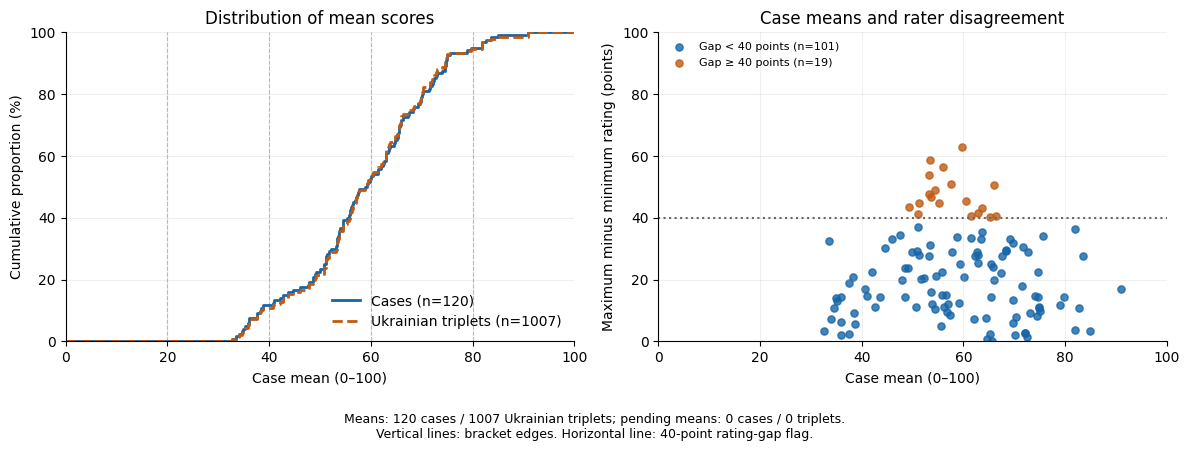

In [7]:
distribution = severity_distribution(taxonomy_with_severity, dataset["rows"]["uk"])
summary = distribution["summary"]
cdf_table = DataFrame(distribution["cdf"])
display(
    DataFrame(
        [
            {"Measure": label, "Value": value}
            for label, value in (
                ("Cases with a mean", str(summary["assigned_cases"])),
                ("Pending case means", str(summary["pending_cases"])),
                ("Case-weighted mean", f"{summary['case_mean']:.2f}"),
                ("Case median", f"{summary['case_median']:.2f}"),
                ("Observed case range", f"{summary['case_min']:.2f}–{summary['case_max']:.2f}"),
                ("Triplets with a case mean", str(summary["assigned_triplets"])),
                ("Triplets with a pending mean", str(summary["pending_triplets"])),
                ("Triplet-weighted mean", f"{summary['triplet_weighted_mean']:.2f}"),
            )
        ]
    )
)
case_bracket_counts = Counter(row["severity_bracket"] for row in taxonomy_with_severity)
unique_triplets = {row["id"]: row for row in triplet_severity["uk"]}
triplet_bracket_counts = Counter(row["severity_bracket"] for row in unique_triplets.values())
bracket_summary = []
cumulative_cases = cumulative_triplets = 0
for level, bracket in enumerate(brackets, 1):
    cases = case_bracket_counts[bracket["code"]]
    triplets = triplet_bracket_counts[bracket["code"]]
    cumulative_cases += cases
    cumulative_triplets += triplets
    bracket_summary.append(
        {
            **bracket,
            "level": level,
            "case_count": cases,
            "triplet_count": triplets,
            "case_fraction": cases / summary["assigned_cases"],
            "triplet_fraction": triplets / summary["assigned_triplets"],
            "cumulative_cases": cumulative_cases,
            "cumulative_triplets": cumulative_triplets,
            "cumulative_case_fraction": cumulative_cases / summary["assigned_cases"],
            "cumulative_triplet_fraction": cumulative_triplets / summary["assigned_triplets"],
        }
    )
bracket_table = DataFrame(bracket_summary)
display(
    DataFrame(
        [
            {
                "Severity level": f"{row['level']} — {row['label']}",
                "Mean interval": interval_label(row),
                "Cases": f"{row['case_count']} ({100 * row['case_fraction']:.2f}%)",
                "Ukrainian triplets": f"{row['triplet_count']} ({100 * row['triplet_fraction']:.2f}%)",
                "Cases through bracket": f"{row['cumulative_cases']} ({100 * row['cumulative_case_fraction']:.2f}%)",
                "Ukrainian triplets through bracket": f"{row['cumulative_triplets']} ({100 * row['cumulative_triplet_fraction']:.2f}%)",
            }
            for row in bracket_summary
        ]
    )
)

figure_png = work / "severity-distribution.png"
figure_svg = work / "severity-distribution.svg"
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
gap_threshold = 100 * protocol["disagreement_threshold"]
if distribution["cdf"]:
    x = [0] + cdf_table["severity_score"].tolist() + [100]
    axes[0].step(
        x,
        [0] + (100 * cdf_table["case_fraction"]).tolist() + [100],
        where="post",
        linewidth=2,
        color="#1565A8",
        label=f"Cases (n={summary['assigned_cases']})",
    )
    axes[0].step(
        x,
        [0] + (100 * cdf_table["triplet_fraction"]).tolist() + [100],
        where="post",
        linewidth=2,
        linestyle="--",
        color="#C05A12",
        label=f"Ukrainian triplets (n={summary['assigned_triplets']})",
    )
axes[0].set(
    xlim=(0, 100),
    ylim=(0, 100),
    xlabel="Case mean (0–100)",
    ylabel="Cumulative proportion (%)",
    title="Distribution of mean scores",
)
for bracket in brackets[1:]:
    axes[0].axvline(bracket["lower"], color="#BBBBBB", linestyle="--", linewidth=0.8, zorder=0)
axes[0].legend(loc="lower right", frameon=False)

for status, color, label in (
    ("aggregated", "#1565A8", f"Gap < {gap_threshold:g} points"),
    ("high_disagreement", "#C05A12", f"Gap ≥ {gap_threshold:g} points"),
):
    selected = [row for row in case_decision_rows if row["severity_status"] == status]
    axes[1].scatter(
        [row["severity_score"] for row in selected],
        [row["rating_gap_100"] for row in selected],
        s=27,
        alpha=0.8,
        color=color,
        label=f"{label} (n={len(selected)})",
    )
axes[1].axhline(gap_threshold, color="#666666", linestyle=":", linewidth=1.5)
axes[1].set(
    xlim=(0, 100),
    ylim=(0, 100),
    xlabel="Case mean (0–100)",
    ylabel="Maximum minus minimum rating (points)",
    title="Case means and rater disagreement",
)
axes[1].legend(loc="upper left", frameon=False, fontsize=8)
for axis in axes:
    axis.grid(alpha=0.2)
    axis.spines[["top", "right"]].set_visible(False)
figure.tight_layout(rect=(0, 0.1, 1, 1))
figure.text(
    0.5,
    0.015,
    f"Means: {summary['assigned_cases']} cases / {summary['assigned_triplets']} Ukrainian triplets; "
    f"pending means: {summary['pending_cases']} cases / {summary['pending_triplets']} triplets.\n"
    f"Vertical lines: bracket edges. Horizontal line: {gap_threshold:g}-point rating-gap flag.",
    ha="center",
    fontsize=9,
)
figure.savefig(figure_png, dpi=180, bbox_inches="tight")
figure.savefig(figure_svg, bbox_inches="tight", metadata={"Date": None, "Creator": "WarBias"})
display(figure)
plt.close(figure)

## Prepare review queues

The large-gap queue shows disagreement among assigned ratings. It preserves
source examples, individual scores, recorded rubric versions and eligibility.
All current cases have assigned means and levels.


In [8]:
review_queues = build_review_queues(taxonomy_with_severity, case_evidence, protocol=protocol)
review_paths = {}
for name, rows in review_queues.items():
    path = work / f"severity-review-{name}.csv"
    table = DataFrame(
        [
            {
                field: canonical_json(value) if isinstance(value, (dict, list)) else value
                for field, value in row.items()
            }
            for row in rows
        ]
    )
    table.to_csv(path, index=False)
    review_paths[name] = path.as_posix()
readiness = {
    "complete": all(row["severity_mean_score"] is not None for row in taxonomy_with_severity),
    "assigned_cases": sum(row["severity_mean_score"] is not None for row in taxonomy_with_severity),
    "pending_cases": len(review_queues["pending"]),
    "large_gap_cases": len(review_queues["large_gaps"]),
}
display(readiness)
display(
    DataFrame(
        [
            {"Review queue": name, "Cases": len(review_queues[name]), "Path": path}
            for name, path in review_paths.items()
        ]
    )
)

{'complete': True,
 'assigned_cases': 120,
 'pending_cases': 0,
 'large_gap_cases': 19}

,Review queue,Cases,Path
0,pending,0,runs/severity_all_ratings/06_severity-_crfsx0g/severity-review-pending.csv
1,large_gaps,19,runs/severity_all_ratings/06_severity-_crfsx0g/severity-review-large_gaps.csv


## Export severity values and audit files

Export the taxonomy with its claims and sources, both language datasets and the
calculation audit. The coverage check requires a mean and level for every case.
Review queues are saved before this check.


In [9]:
if REQUIRE_COMPLETE:
    require_final_labels(taxonomy_with_severity)

taxonomy_csv = work / "taxonomy-severity.csv"
taxonomy_jsonl = work / "taxonomy-severity.jsonl"
csv_table = case_table.copy()
csv_table["severity_ratings"] = csv_table["severity_ratings"].map(canonical_json)
csv_table.to_csv(taxonomy_csv, index=False)
write_rows(taxonomy_jsonl, taxonomy_with_severity)
assert read_rows(taxonomy_jsonl) == taxonomy_with_severity
sidecar_paths = {}
for language, rows in triplet_severity.items():
    path = work / f"triplet-severity-{language}.jsonl"
    write_rows(path, rows)
    assert read_rows(path) == rows
    sidecar_paths[language] = path.as_posix()
dataset_paths = {}
for language, rows in dataset_with_severity.items():
    path = work / f"dataset-with-severity-{language}.jsonl"
    write_rows(path, rows, columns=dataset["protocol"]["columns"])
    assert read_rows(path) == rows
    dataset_paths[language] = path.as_posix()
decision_csv = work / "case-decisions.csv"
decision_jsonl = work / "case-decisions.jsonl"
decision_table = DataFrame(case_decision_rows)
for field in ("eligible_scores_100", "excluded_ratings"):
    decision_table[field] = decision_table[field].map(canonical_json)
decision_table.to_csv(decision_csv, index=False)
write_rows(decision_jsonl, case_decision_rows)
assert read_rows(decision_jsonl) == case_decision_rows
cdf_csv = work / "severity-cdf.csv"
cdf_table.to_csv(cdf_csv, index=False)
level_csv = work / "severity-levels.csv"
bracket_table.to_csv(level_csv, index=False)
summary_json = work / "severity-summary.json"
write_json(summary_json, summary)
result = {
    "stage": "severity",
    "status": "verified_saved_severity",
    "primary_fields": ["severity_mean_score", "severity_level"],
    "taxonomy_binding": taxonomy_binding,
    "scope": scope,
    "source_ratings": len(ratings),
    "current_case_ratings": len(current_ratings),
    "taxonomy_cases": len(taxonomy_with_severity),
    "assigned_cases": readiness["assigned_cases"],
    "pending_cases": readiness["pending_cases"],
    "case_status_counts": dict(case_status_counts),
    "triplets_per_language": {key: len(rows) for key, rows in dataset_with_severity.items()},
    "assigned_triplets_per_language": {
        key: sum(row["severity_mean_score"] is not None for row in rows)
        for key, rows in dataset_with_severity.items()
    },
    "pending_triplets_per_language": {
        key: sum(row["severity_mean_score"] is None for row in rows)
        for key, rows in dataset_with_severity.items()
    },
    "taxonomy_csv": taxonomy_csv.as_posix(),
    "taxonomy_jsonl": taxonomy_jsonl.as_posix(),
    "triplet_sidecars": sidecar_paths,
    "datasets": dataset_paths,
    "readiness": readiness,
    "review_queues": review_paths,
    "review_case_counts": {key: len(rows) for key, rows in review_queues.items()},
    "analysis": {
        "summary": summary,
        "case_decisions_csv": decision_csv.as_posix(),
        "case_decisions_jsonl": decision_jsonl.as_posix(),
        "cdf_csv": cdf_csv.as_posix(),
        "level_summary_csv": level_csv.as_posix(),
        "summary_json": summary_json.as_posix(),
        "figure_png": figure_png.as_posix(),
        "figure_svg": figure_svg.as_posix(),
    },
}
write_json(work / "severity-result.json", result)
display(
    DataFrame(
        [
            {
                "Data file": f"{language.upper()} dataset with severity",
                "Rows": len(dataset_with_severity[language]),
                "Path": path,
            }
            for language, path in dataset_paths.items()
        ]
    )
)

,Data file,Rows,Path
0,UK dataset with severity,1007,runs/severity_all_ratings/06_severity-_crfsx0g/dataset-with-severity-uk.jsonl
1,EN dataset with severity,1007,runs/severity_all_ratings/06_severity-_crfsx0g/dataset-with-severity-en.jsonl
